# 05 — Modelado y comparación de modelos

## Objetivo

Entrenar varios modelos con las 11 variables seleccionadas, compararlos de forma justa y
elegir cuál pasa a la etapa final. El cuadernillo debe dejar claro:

1. contra qué se compara un modelo para saber si aporta algo (líneas base);
2. por qué se prueba cada modelo y qué se espera de él;
3. qué problemas aparecen al entrenar y cómo se resuelven;
4. cuál modelo es mejor en datos que no vio, y con qué criterio.

Se entrena con 2021–2024 y se compara en **validación (2025)**. El conjunto de prueba (2026)
no se toca en este cuadernillo.

In [1]:
import sys
sys.path.append("..")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from sklearn.calibration import calibration_curve
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from src.config import CONFIG_PATH, MODELS_DIR, PROCESSED_DIR, TABLES_DIR, load_config
from src.evaluation import evaluate, temporal_split
from src.plotting import set_style, save_fig

set_style()
config = load_config()
FEATURES, TARGET, SEED = config["features"], config["target"], config["seed"]

dataset = pd.read_csv(PROCESSED_DIR / "dataset.csv")
train, val, test = temporal_split(dataset, config["split"])
X_val, y_val = val[FEATURES], val[TARGET]
print(f"Entrenamiento: {len(train)} mapas | Validación: {len(val)} mapas | Variables: {len(FEATURES)}")

Entrenamiento: 25210 mapas | Validación: 1272 mapas | Variables: 11


## 1. Cómo se mide un modelo

Se usan tres métricas, porque cada una responde una pregunta distinta:

- **Exactitud (*accuracy*):** ¿en qué proporción de mapas acierta el ganador? Es la más fácil de interpretar.
- **ROC-AUC:** ¿qué tan bien *ordena* los mapas de menos a más favorables para Team A? No
  depende del umbral de decisión. 0.5 es azar.
- **Log loss:** ¿qué tan buenas son las *probabilidades*? Castiga mucho al modelo que se
  equivoca estando muy seguro. Responder siempre "50 %" da 0.693; **un log loss mayor que
  0.693 es peor que no saber nada**.

El log loss es el criterio principal de este proyecto. En un problema con tanto azar como
este, lo útil de un modelo no es decir "gana A", sino decir "A tiene 62 % de probabilidad" y
que eso sea cierto.

Todas se calculan con `evaluate()` de `src/evaluation.py`.

## 2. Líneas base

Antes de entrenar nada se fijan las referencias mínimas. Un modelo que no las supere no aporta.

- **Clase mayoritaria:** predecir siempre la proporción de victorias de Team A en entrenamiento (≈ 50 %).
- **Regla del winrate:** gana el equipo con mejor winrate histórico (la regla del cuadernillo 02).
  Como da un veredicto y no una probabilidad, solo se le puede medir la exactitud.
- **Logística de una variable:** una regresión logística que solo usa `diff_winrate`. Es la
  versión "con probabilidades" de la regla anterior.

In [2]:
results = {}

results["Base: clase mayoritaria"] = evaluate(y_val, np.full(len(val), train[TARGET].mean()))

rule_proba = np.select([val["diff_winrate"] > 0, val["diff_winrate"] < 0], [1.0, 0.0], default=0.5)
rule_accuracy = ((rule_proba > 0.5) == (y_val == 1))[rule_proba != 0.5].mean()
results["Base: regla del winrate"] = {"accuracy": rule_accuracy, "roc_auc": np.nan, "log_loss": np.nan}
print(f"La regla no decide en el {(rule_proba == 0.5).mean():.1%} de los mapas (sin historial o empate)")

one_variable = make_pipeline(SimpleImputer(strategy="median"), LogisticRegression())
one_variable.fit(train[["diff_winrate"]], train[TARGET])
results["Base: logística de 1 variable"] = evaluate(y_val, one_variable.predict_proba(val[["diff_winrate"]])[:, 1])

pd.DataFrame(results).T.round(4)

La regla no decide en el 3.5% de los mapas (sin historial o empate)


,accuracy,roc_auc,log_loss
Base: clase mayoritaria,0.4976,0.500,0.6932
Base: regla del winrate,0.5778,NaN,NaN
Base: logística de 1 variable,0.5692,0.592,0.6801


Son referencias exigentes. La regla simple acierta el 57.8 % en 2025 sin aprender nada, y
la logística de una sola variable ya convierte esa regla en probabilidades útiles (log loss
0.680, por debajo del 0.693 de no saber nada). Cualquier modelo más complejo tiene que
justificar su complejidad frente a estas dos.

## 3. Primer intento y un problema: el modelo se pasa de confiado

Se entrena una regresión logística con las 11 variables y todo el conjunto de entrenamiento.

Como la logística no admite valores faltantes, se rellenan con la mediana y se agrega, por
cada variable, un indicador de "este dato faltaba" (`add_indicator=True`), para que el modelo
pueda distinguir un valor real de uno rellenado. Las variables se estandarizan porque están
en escalas muy distintas.

In [3]:
def make_logistic():
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                         LogisticRegression(max_iter=2000))

first_try = make_logistic().fit(train[FEATURES], train[TARGET])
first_proba = first_try.predict_proba(X_val)[:, 1]
pd.Series(evaluate(y_val, first_proba)).round(4)

accuracy    0.5668
roc_auc     0.5899
log_loss    0.8406
dtype: float64

Exactitud y AUC normales, pero un log loss de 0.84: mucho peor que no saber nada. Se miran
las probabilidades que entrega.

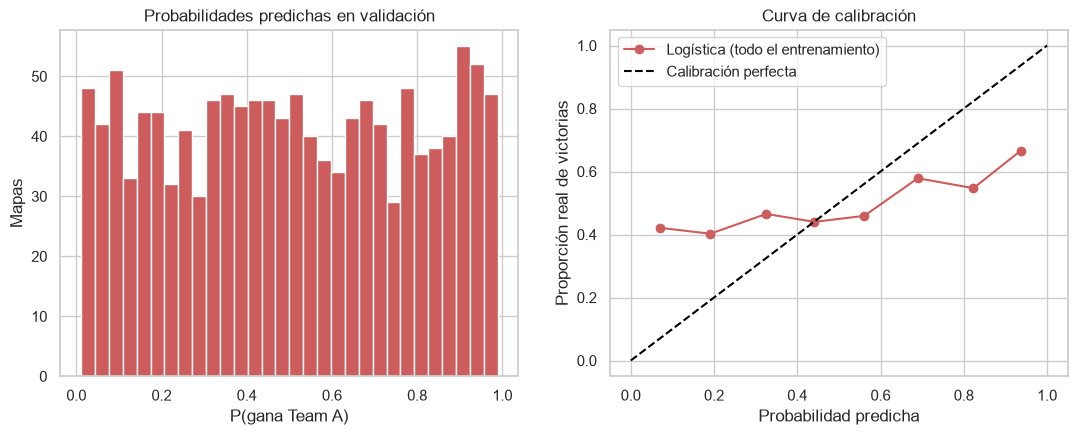

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(first_proba, bins=30, color="indianred")
axes[0].set(title="Probabilidades predichas en validación", xlabel="P(gana Team A)", ylabel="Mapas")

observed, predicted = calibration_curve(y_val, first_proba, n_bins=8, strategy="quantile")
axes[1].plot(predicted, observed, marker="o", color="indianred", label="Logística (todo el entrenamiento)")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="black", label="Calibración perfecta")
axes[1].set(title="Curva de calibración", xlabel="Probabilidad predicha", ylabel="Proporción real de victorias")
axes[1].legend()
save_fig("05_problema_calibracion")
plt.show()

El modelo reparte probabilidades de 1 % a 99 % de forma casi uniforme, como si muchos
partidos estuvieran decididos de antemano. La curva de calibración lo desmiente: cuando dice
"más de 90 %", Team A gana solo dos de cada tres veces; cuando dice "menos de 10 %", gana el
42 %. La curva es casi plana, cuando debería seguir la diagonal.

**¿Por qué?** Se comparan las variables en entrenamiento y en validación.

In [5]:
shift = pd.DataFrame({
    "std_train": train[FEATURES].std(), "std_val": val[FEATURES].std(),
    "median_train": train[FEATURES].median(), "median_val": val[FEATURES].median(),
}).round(2)
shift.loc[["diff_maps_played", "min_maps_played", "diff_winrate", "diff_round_diff", "diff_acs"]]

,std_train,std_val,median_train,median_val
diff_maps_played,41.43,158.57,0.00,-2.00
min_maps_played,40.02,99.37,4.00,106.00
diff_winrate,0.24,0.16,0.00,0.00
diff_round_diff,3.80,2.44,0.00,-0.01
diff_acs,17.79,9.11,0.01,0.30


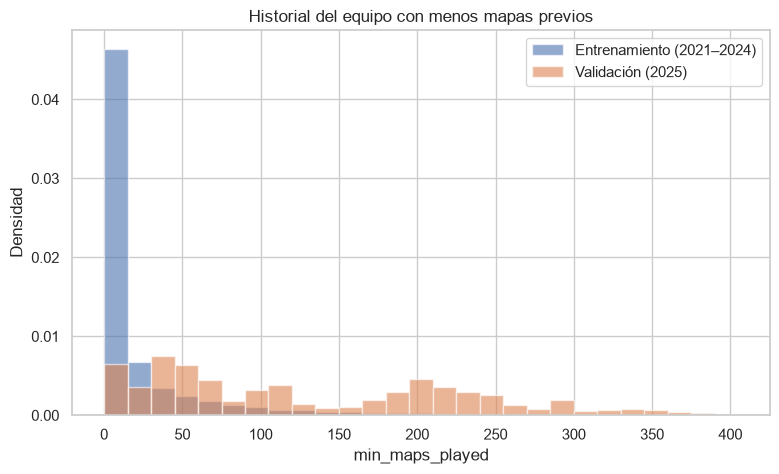

Mapas con ambos equipos con 30+ mapas previos → entrenamiento: 20.3% | validación: 85.1%


In [6]:
fig, ax = plt.subplots()
bins = np.arange(0, 420, 15)
ax.hist(train["min_maps_played"], bins=bins, density=True, alpha=0.6, label="Entrenamiento (2021–2024)")
ax.hist(val["min_maps_played"], bins=bins, density=True, alpha=0.6, label="Validación (2025)")
ax.set(title="Historial del equipo con menos mapas previos", xlabel="min_maps_played", ylabel="Densidad")
ax.legend()
save_fig("05_historial_train_vs_val")
plt.show()

print(f"Mapas con ambos equipos con 30+ mapas previos → entrenamiento: "
      f"{(train['min_maps_played'] >= 30).mean():.1%} | validación: {(val['min_maps_played'] >= 30).mean():.1%}")

**El entrenamiento y la validación describen dos mundos distintos.**

- En entrenamiento domina 2021–2022: clasificatorios abiertos, equipos con pocos mapas y
  partidos muy desiguales. Ahí una diferencia de experiencia de 40 mapas es enorme y casi
  decide el partido.
- En 2025 todos son equipos de liga con cientos de mapas. Diferencias de 150 o 300 mapas son
  normales (dependen de cuántos años lleva el equipo en el circuito) y no significan gran cosa.

El modelo aprendió "40 mapas de ventaja = favorito claro" y, al ver 300 mapas de diferencia,
extrapola a una certeza absurda. La culpable es la variable de experiencia
(`diff_maps_played`): su dispersión en validación es casi cuatro veces la de entrenamiento.
La logística de una variable, que no la usa, no tiene este problema.

## 4. Solución: entrenar con partidos comparables a los que se quiere predecir

El objetivo del proyecto es predecir mapas del VCT actual, donde ambos equipos llegan con
historial. Tiene sentido entrenar con mapas de ese mismo tipo: aquellos en los que **los dos
equipos ya tenían un historial sustancial**. Los mapas de clasificatorios abiertos siguen
siendo útiles —alimentan el historial de los equipos— pero no como ejemplos de entrenamiento.

Para elegir el umbral se prueba la logística con distintos mínimos de mapas previos.

In [7]:
rows = []
for threshold in [0, 5, 10, 20, 30, 50, 80]:
    subset = train[train["min_maps_played"] >= threshold]
    model = make_logistic().fit(subset[FEATURES], subset[TARGET])
    rows.append({"min_maps_played >=": threshold, "train_maps": len(subset),
                 **evaluate(y_val, model.predict_proba(X_val)[:, 1])})
sensitivity = pd.DataFrame(rows).set_index("min_maps_played >=")
sensitivity.to_csv(TABLES_DIR / "05_sensibilidad_umbral_historial.csv")
sensitivity.round(4)

,train_maps,accuracy,roc_auc,log_loss
min_maps_played >=,,,,
0,25210,0.5668,0.5899,0.8406
5,11911,0.5676,0.5919,0.7329
10,9276,0.5637,0.5923,0.7163
20,6481,0.5629,0.5904,0.7021
30,5106,0.5723,0.5986,0.6878
50,3451,0.5597,0.5831,0.6960
80,1959,0.5668,0.5953,0.6864


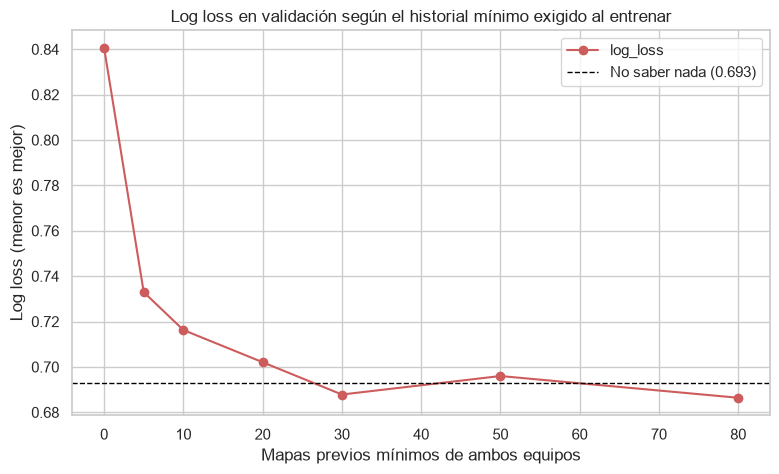

In [8]:
ax = sensitivity["log_loss"].plot(marker="o", color="indianred")
ax.axhline(0.693, color="black", linestyle="--", linewidth=1, label="No saber nada (0.693)")
ax.set(title="Log loss en validación según el historial mínimo exigido al entrenar",
       xlabel="Mapas previos mínimos de ambos equipos", ylabel="Log loss (menor es mejor)")
ax.legend()
save_fig("05_sensibilidad_umbral_historial")
plt.show()

El log loss baja de forma sostenida al exigir más historial y cruza la referencia de 0.693
alrededor de 30 mapas; a partir de ahí oscila sin mejorar, mientras el conjunto de
entrenamiento sigue encogiéndose. La exactitud y el AUC apenas cambian: lo que mejora es la **calibración**.

Hay una alternativa más directa: quitar las variables de experiencia y seguir entrenando
con todo.

In [9]:
without_experience = [f for f in FEATURES if f not in ("diff_maps_played", "min_maps_played")]
alternative = make_logistic().fit(train[without_experience], train[TARGET])
pd.Series(evaluate(y_val, alternative.predict_proba(val[without_experience])[:, 1])).round(4)

accuracy    0.5723
roc_auc     0.5880
log_loss    0.6842
dtype: float64

También corrige la calibración (log loss 0.684), y la diferencia con filtrar (0.688) es
demasiado pequeña para decidir entre las dos por el número. Se elige **filtrar** por
razonamiento: conserva la experiencia —la variable más informativa del cuadernillo 04— y,
sobre todo, ataca la causa (se entrena con partidos que no se parecen a los que se quiere
predecir) en lugar del síntoma.

**Decisión:** entrenar solo con mapas donde ambos equipos tienen al menos **30 mapas previos**.
Es el punto donde el problema desaparece sin sacrificar más datos de los necesarios, y
coincide con el tipo de partido que se quiere predecir (el 85 % de la validación cumple esa
condición, frente al 20 % del entrenamiento). El umbral se guarda en `config.yaml`.

La evaluación **no** se filtra: se sigue midiendo sobre todos los mapas de 2025.

In [10]:
MIN_HISTORY = 30
config["min_train_history"] = MIN_HISTORY
CONFIG_PATH.write_text(yaml.safe_dump(config, sort_keys=False, allow_unicode=True), encoding="utf-8")

train_fit = train[train["min_maps_played"] >= MIN_HISTORY]
X_train, y_train = train_fit[FEATURES], train_fit[TARGET]
print(f"Mapas de entrenamiento: {len(train)} → {len(train_fit)}")
train_fit["year"].value_counts().sort_index().to_frame("maps").T

Mapas de entrenamiento: 25210 → 5106


year,2021,2022,2023,2024
maps,1608,2017,585,896


## 5. Modelos candidatos

Se prueban tres modelos de familias distintas, de menor a mayor complejidad. Los tres se
entrenan con los mismos datos y las mismas variables.

### 5.1 Regresión logística

**Por qué se prueba:** es el modelo más simple para clasificación binaria y el punto de
partida natural. Supone que cada variable empuja la probabilidad en una dirección fija
(más ventaja de winrate → más probabilidad de ganar), que es justo lo que se observó en el
cuadernillo 02. Sus ventajas aquí: es **interpretable** (cada coeficiente dice cuánto pesa una
variable), produce probabilidades bien calibradas por construcción y, con pocos parámetros,
es difícil que se sobreajuste a un conjunto de unos miles de mapas.

**Límite:** no capta interacciones (por ejemplo, que el winrate importe más cuando hay mucho
historial) ni relaciones no lineales, salvo que se le construyan a mano.

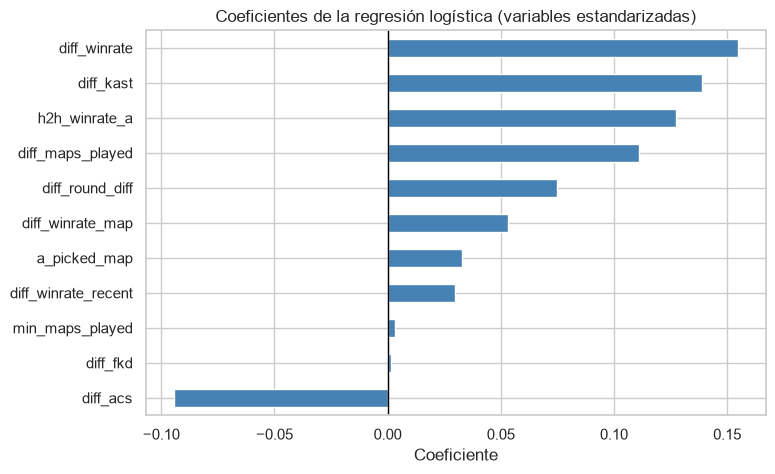

accuracy    0.5723
roc_auc     0.5986
log_loss    0.6878
dtype: float64

In [11]:
models = {}
models["Regresión logística"] = make_logistic().fit(X_train, y_train)
results["Regresión logística"] = evaluate(y_val, models["Regresión logística"].predict_proba(X_val)[:, 1])

logistic = models["Regresión logística"]
coefficients = pd.Series(logistic[-1].coef_[0], index=logistic[:-1].get_feature_names_out())
coefficients = coefficients[~coefficients.index.str.startswith("missingindicator")].sort_values()
ax = coefficients.plot.barh(color="steelblue", figsize=(8, 5))
ax.axvline(0, color="black", linewidth=1)
ax.set(title="Coeficientes de la regresión logística (variables estandarizadas)", xlabel="Coeficiente")
save_fig("05_coeficientes_logistica")
plt.show()
pd.Series(results["Regresión logística"]).round(4)

Los coeficientes son pequeños y están repartidos: winrate, KAST, enfrentamientos directos y
experiencia empujan en el sentido esperado. `diff_acs` aparece con signo negativo, lo que no
significa que tener mejor ACS perjudique: está muy correlacionada con `diff_round_diff` y
`diff_kast` (cuadernillo 04) y, cuando varias variables cuentan lo mismo, la logística
reparte el peso entre ellas de forma inestable. Es el costo de haber conservado variables
correlacionadas, y una razón para no leer estos coeficientes uno por uno.

### 5.2 Random Forest

**Por qué se prueba:** promedia cientos de árboles de decisión entrenados sobre muestras
distintas de los datos. Cada árbol puede captar **no linealidades e interacciones** que la
logística no ve, y el promedio reduce la varianza. Es robusto a valores atípicos y a variables
en escalas distintas, y funciona razonablemente bien sin ajustar casi nada.

**Configuración:** 300 árboles y hojas de al menos 20 mapas (`min_samples_leaf=20`). Con una
señal tan débil, dejar que los árboles crezcan hasta hojas de un solo mapa haría que
memorizaran ruido; exigir 20 mapas por hoja obliga a que cada probabilidad salga de un grupo
con algo de respaldo. Los faltantes se rellenan igual que en la logística.

**Límite:** menos interpretable, y sus probabilidades tienden a encogerse hacia el centro.

In [12]:
models["Random Forest"] = make_pipeline(
    SimpleImputer(strategy="median", add_indicator=True),
    RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=SEED, n_jobs=-1),
).fit(X_train, y_train)
results["Random Forest"] = evaluate(y_val, models["Random Forest"].predict_proba(X_val)[:, 1])
pd.Series(results["Random Forest"]).round(4)

accuracy    0.5637
roc_auc     0.5810
log_loss    0.6884
dtype: float64

### 5.3 Gradient Boosting

**Por qué se prueba:** construye árboles pequeños en secuencia, cada uno corrigiendo los
errores de los anteriores. En datos tabulares suele ser la familia de modelos con mejor
desempeño. Se usa `HistGradientBoostingClassifier` de scikit-learn, que además **maneja los
valores faltantes de forma nativa**: en cada división aprende hacia qué lado enviar los
faltantes, sin necesidad de rellenarlos. Eso encaja bien con este dataset, donde "no hay
dato" tiene significado propio.

**Configuración:** árboles de profundidad 3, tasa de aprendizaje 0.05 y parada temprana
(deja de agregar árboles cuando una parte reservada del entrenamiento deja de mejorar). Son
valores conservadores a propósito: con unos 5 000 mapas y poca señal, un boosting con la
configuración por defecto se sobreajusta. Se muestra la diferencia.

**Límite:** es el más propenso a sobreajustarse y el que más depende de sus hiperparámetros.

In [13]:
default_boosting = HistGradientBoostingClassifier(random_state=SEED).fit(X_train, y_train)
print("Boosting con configuración por defecto:",
      {k: round(v, 4) for k, v in evaluate(y_val, default_boosting.predict_proba(X_val)[:, 1]).items()})

models["Gradient Boosting"] = HistGradientBoostingClassifier(
    max_depth=3, learning_rate=0.05, early_stopping=True, random_state=SEED).fit(X_train, y_train)
results["Gradient Boosting"] = evaluate(y_val, models["Gradient Boosting"].predict_proba(X_val)[:, 1])
print("Árboles usados tras la parada temprana:", models["Gradient Boosting"].n_iter_)
pd.Series(results["Gradient Boosting"]).round(4)

Boosting con configuración por defecto: {'accuracy': 0.5401, 'roc_auc': 0.5618, 'log_loss': 0.7397}
Árboles usados tras la parada temprana: 42


accuracy    0.5755
roc_auc     0.5974
log_loss    0.6802
dtype: float64

## 6. Comparación

In [14]:
comparison = pd.DataFrame(results).T
comparison.to_csv(TABLES_DIR / "05_comparacion_modelos.csv")
comparison.round(4)

,accuracy,roc_auc,log_loss
Base: clase mayoritaria,0.4976,0.5000,0.6932
Base: regla del winrate,0.5778,NaN,NaN
Base: logística de 1 variable,0.5692,0.5920,0.6801
Regresión logística,0.5723,0.5986,0.6878
Random Forest,0.5637,0.5810,0.6884
Gradient Boosting,0.5755,0.5974,0.6802


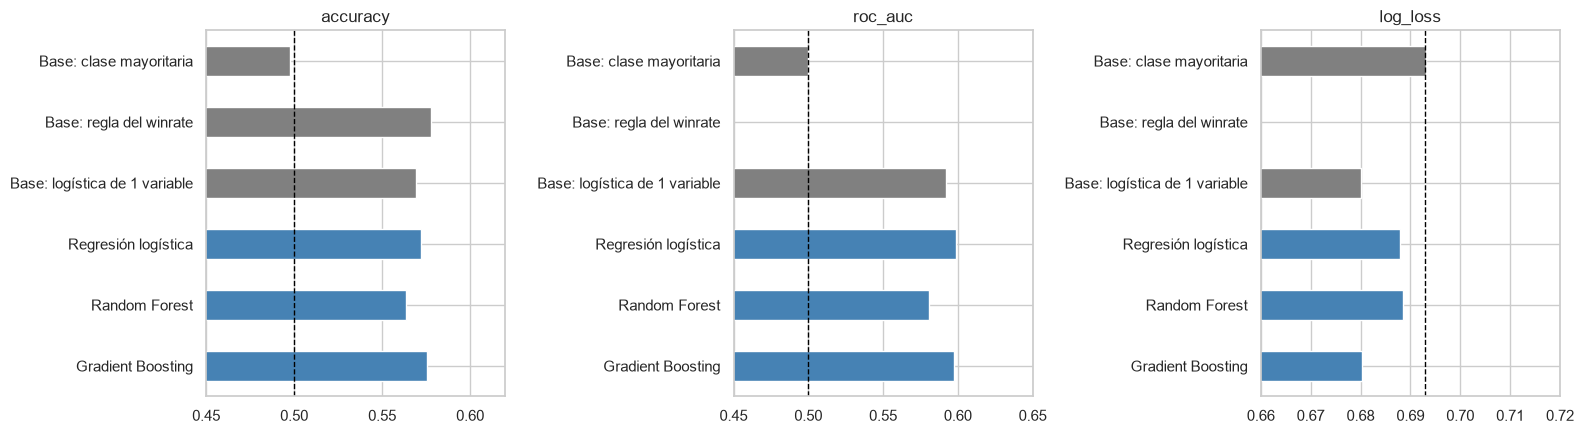

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
colors = ["grey" if name.startswith("Base") else "steelblue" for name in comparison.index]
for ax, (metric, reference, limits) in zip(axes, [("accuracy", 0.5, (0.45, 0.62)),
                                                   ("roc_auc", 0.5, (0.45, 0.65)),
                                                   ("log_loss", 0.693, (0.66, 0.72))]):
    comparison[metric].plot.barh(ax=ax, color=colors)
    ax.axvline(reference, color="black", linestyle="--", linewidth=1)
    ax.set(title=metric, xlim=limits)
    ax.invert_yaxis()
plt.tight_layout()
save_fig("05_comparacion_modelos")
plt.show()

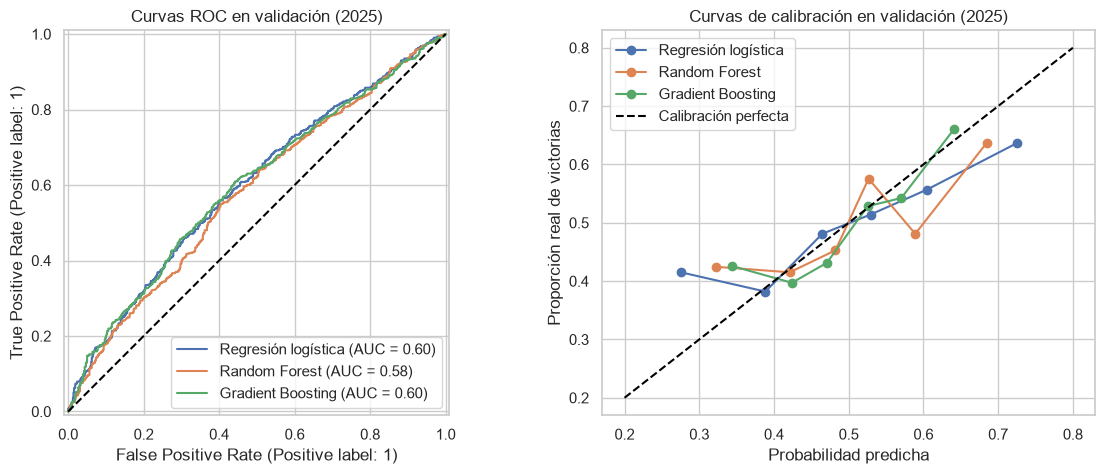

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, model in models.items():
    proba = model.predict_proba(X_val)[:, 1]
    RocCurveDisplay.from_predictions(y_val, proba, name=name, ax=axes[0])
    observed, predicted = calibration_curve(y_val, proba, n_bins=6, strategy="quantile")
    axes[1].plot(predicted, observed, marker="o", label=name)
axes[0].plot([0, 1], [0, 1], linestyle="--", color="black")
axes[0].set(title="Curvas ROC en validación (2025)")
axes[1].plot([0.2, 0.8], [0.2, 0.8], linestyle="--", color="black", label="Calibración perfecta")
axes[1].set(title="Curvas de calibración en validación (2025)", xlabel="Probabilidad predicha",
            ylabel="Proporción real de victorias")
axes[1].legend()
save_fig("05_roc_y_calibracion")
plt.show()

**¿Qué tan seguras son estas diferencias?** La validación tiene 1 272 mapas. Con una
exactitud cercana al 57 %, el error estándar es de unos 1.4 puntos porcentuales, así que
diferencias de uno o dos puntos entre modelos están dentro del ruido.

In [17]:
n = len(val)
for name in models:
    acc = results[name]["accuracy"]
    half_width = 1.96 * np.sqrt(acc * (1 - acc) / n)
    print(f"{name:<22} exactitud {acc:.3f}  (IC 95 %: {acc - half_width:.3f} – {acc + half_width:.3f})")

Regresión logística    exactitud 0.572  (IC 95 %: 0.545 – 0.600)
Random Forest          exactitud 0.564  (IC 95 %: 0.536 – 0.591)
Gradient Boosting      exactitud 0.575  (IC 95 %: 0.548 – 0.603)


## 7. Guardar los modelos

In [18]:
file_names = {"Regresión logística": "logistic_regression", "Random Forest": "random_forest",
              "Gradient Boosting": "hist_gradient_boosting"}
for name, model in models.items():
    path = MODELS_DIR / f"{file_names[name]}.joblib"
    joblib.dump(model, path, compress=3)
    print(f"{path.name:<32} {path.stat().st_size / 1e6:.2f} MB")

logistic_regression.joblib       0.00 MB
random_forest.joblib             2.00 MB
hist_gradient_boosting.joblib    0.03 MB


## Conclusiones

1. **Las líneas base son difíciles de batir.** En validación (2025), la regla "gana el de
   mejor winrate" acierta el 57.8 % y una logística con esa única variable logra log loss 0.680.
2. **Problema encontrado y resuelto:** entrenada con todos los datos, la logística de 11
   variables queda muy mal calibrada (log loss 0.84). La causa es que el entrenamiento está
   dominado por clasificatorios de 2021–2022 y la variable de experiencia cambia de escala en
   las ligas actuales. Entrenar solo con mapas donde ambos equipos tienen 30 o más mapas
   previos (5 106 de 25 210) lo corrige.
3. **Resultados en validación:**

   | Modelo | Exactitud | ROC-AUC | Log loss |
   |---|---|---|---|
   | Base: clase mayoritaria | 0.498 | 0.500 | 0.693 |
   | Base: regla del winrate | 0.578 | — | — |
   | Base: logística de 1 variable | 0.569 | 0.592 | 0.680 |
   | Regresión logística | 0.572 | 0.599 | 0.688 |
   | Random Forest | 0.564 | 0.581 | 0.688 |
   | **Gradient Boosting** | **0.575** | 0.597 | **0.680** |

4. **Modelo que pasa a la etapa final: Gradient Boosting.** Con el criterio fijado de
   antemano (menor log loss en validación) es el mejor de los tres candidatos, y también el
   de mayor exactitud. La regresión logística queda muy cerca y tiene el mejor AUC.
5. **Hay que decirlo con claridad: ningún modelo supera de forma convincente a las líneas
   base.** El Gradient Boosting empata en log loss con la logística de una variable y queda
   dentro del margen de error de la regla simple (IC 95 % de su exactitud: 54.8 %–60.3 %).
   Las 11 variables aportan, como mucho, una mejora marginal sobre el winrate solo.
6. **Lo que sí enseña la comparación:** la configuración importa más que la familia de
   modelo. El mismo boosting pasa de log loss 0.740 (por defecto, sobreajustado) a 0.680
   (árboles pequeños y parada temprana), y la misma logística pasa de 0.84 a 0.688 solo
   cambiando con qué datos se entrena.
7. Los tres modelos quedan guardados en `models/`.

**Siguiente paso (cuadernillo 06):** ajustar los hiperparámetros del Gradient Boosting y
evaluarlo, una sola vez, en el conjunto de prueba (2026), junto con las líneas base.